In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

plt.rc('font', **{'family':'sans-serif','sans-serif':['Arial'], 'size': 8})
plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "font.family": "sans-serif", "axes.linewidth": 0.7, "xtick.major.width": 0.7,
    "ytick.major.width": 0.7, "xtick.major.size": 3.0, "ytick.major.size": 3.0, "savefig.dpi": 600,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


hexcolors = [
    '#D1B8D7', '#AE76A3', '#882E72',
    '#1965B0', '#5289C7', '#7BAFDE',
    '#4EB265', '#90C987', '#CAE0AB',
    '#F7F056', '#F6C141', '#F1932D',
    '#E8601C', '#DC050C', '#777777',
    '#000000'
]
 
colornames = ['purple1','purple2','purple3',
    'blue1','blue2','blue3',
    'green1','green2','green3',
    'yellow1','yellow2','orange1',
    'orange2','red','grey', 'black']
 
rnb_colors = dict(zip(colornames, hexcolors))

aSyn 0
aSyn 1
aSyn 2
aSyn 0
aSyn 1
aSyn 2
aSyn 2
aSyn_LH 0
aSyn_LH 1
aSyn_LH 2
aSyn_LH 0
aSyn_LH 1
aSyn_LH 2
aSyn_LH 0


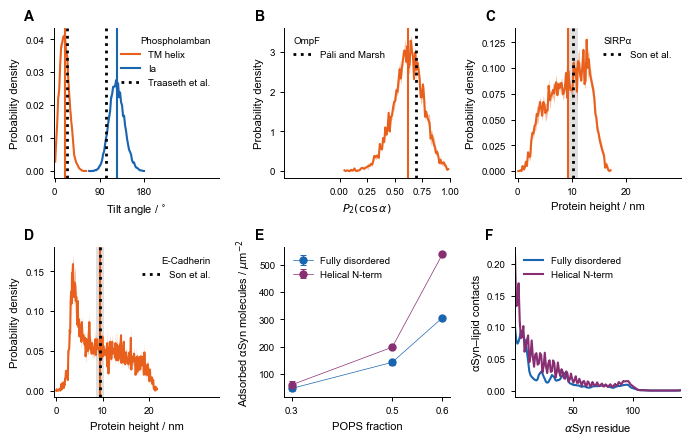

In [17]:
def hist_stats(xs, bins):
    h = np.array([np.histogram(x, bins=bins, density=True)[0] for x in xs])
    p = np.histogram(np.concatenate(xs), bins=bins, density=True)[0]
    x = (bins[:-1] + bins[1:]) / 2
    return x, p, h.std(0)/np.sqrt(len(xs)), np.concatenate(xs).mean()

fig, ax = plt.subplots(2, 3, figsize=(7, 4.5))
ax = ax.ravel()

# --- phospholamban (2KB7) ---
a1, a2 = [], []
for i in range(3):
    d = np.load(f'data/exp_valid/2KB7_{i}_domain_angles.npy', allow_pickle=True).item()
    a1.append(np.minimum(d['TMD'][100:], 180 - d['TMD'][100:]))
    if i == 1:
        a2.append(180 - d['la'][100:])
    else:
        a2.append(d['la'][100:])

"""bins = np.arange(np.floor(min(np.concatenate(a1).min(), np.concatenate(a2).min())),
                 np.ceil(max(np.concatenate(a1).max(), np.concatenate(a2).max())) + 2, 2)

for y in a2:
    x = (bins[:-1] + bins[1:]) / 2
    ax[0].plot(x,np.histogram(y, bins=bins, density=True)[0])"""

for arr, c, lab, exp, explab in [(a1, 'orange2', 'TM helix', 24,  ''),
                                 (a2, 'blue1',   'Ia', 102, 'Traaseth et al.')]:
    bins = np.arange(np.min(arr),np.max(arr) + 2, 2)
    x, p, se, m = hist_stats(arr, bins)
    ax[0].plot(x, p, color=rnb_colors[c], lw=1.5, label=lab)
    ax[0].fill_between(x, p-se, p+se, color=rnb_colors[c], alpha=.4, lw=0)
    ax[0].axvline(m, color=rnb_colors[c], lw=1.5)
    ax[0].axvline(exp, color='k', ls=':', lw=2, label=explab)

ax[0].set(xlabel='Tilt angle / $^{\\circ}$', ylabel='Probability density')
leg = ax[0].legend(frameon=False, fontsize=7, title='Phospholamban', title_fontsize=7)
leg._legend_box.align = "right"
ax[0].set_xlim(-2, 330)
ax[0].set_xticks([0, 90, 180])

# --- 2OMF ---
p2 = []
for i in range(3):
    a = np.load(f'data/exp_valid/2OMF_{i}_domain_angles.npy', allow_pickle=True).item()['TMD'][100:, 0]
    p2.append(0.5 * (3*np.cos(np.radians(a))**2 - 1))

bins = np.arange(np.floor(np.concatenate(p2).min()*100)/100,
                 np.ceil(np.concatenate(p2).max()*100)/100 + 0.01, 0.01)
x, p, se, m = hist_stats(p2, bins)

ax[1].plot(x, p, color=rnb_colors['orange2'], lw=1.5)
ax[1].fill_between(x, p-se, p+se, color=rnb_colors['orange2'], alpha=.4, lw=0)
ax[1].axvline(m, color=rnb_colors['orange2'], lw=1.5)
ax[1].axvline(0.69, color='k', ls=':', lw=2, label='Páli and Marsh')
ax[1].set(xlabel=r'$P_2(\cos\alpha)$', ylabel='Probability density')
leg = ax[1].legend(frameon=False, fontsize=7, title='OmpF', title_fontsize=7)
leg._legend_box.align = "left"
ax[1].set_xlim(-0.5, 1)
ax[1].set_xticks([0,0.25, 0.5,0.75, 1])

# --- Sirpa ---
sirpa = [np.load(f'data/exp_valid/Sirpa_{i}_height.npy') for i in range(3)]
bins = np.arange(0, np.concatenate(sirpa).max() + 0.2, 0.2)
x, p, se, m = hist_stats(sirpa, bins)
ax[2].plot(x, p, color=rnb_colors['orange2'], lw=1.5)
ax[2].fill_between(x, p-se, p+se, color=rnb_colors['orange2'], alpha=.4, lw=0)
ax[2].axvline(m, color=rnb_colors['orange2'], lw=1.5)

for val, lo, hi, lab, color in [(10.2, 9.4, 11.1, 'Son et al.','orange1'),
                         (7.3,  6.4,  8.2, 'Son et al. (His$_{10}$)','blue1')][:1]:
    ax[2].axvline(val, color='k', ls=':', lw=2, label=lab)
    ax[2].axvspan(lo, hi, color='k', alpha=.12, lw=0)

ax[2].set(xlabel='Protein height / nm', ylabel='Probability density')
leg = ax[2].legend(frameon=False, fontsize=7, title='SIRPα', title_fontsize=7)
leg._legend_box.align = "left"
ax[2].set_xlim(-.5,30)
ax[2].set_xticks([0,10,20])

# --- Cdh1 ---
cdh1 = [np.load(f'data/exp_valid/Cdh1_{i}_height.npy') for i in range(3)]
bins = np.arange(0, np.concatenate(cdh1).max() + 0.1, 0.1)
x, p, se, m = hist_stats(cdh1, bins)

ax[3].plot(x, p, color=rnb_colors['orange2'], lw=1.5)
ax[3].fill_between(x, p-se, p+se, color=rnb_colors['orange2'], alpha=.4, lw=0)
ax[3].axvline(m, color=rnb_colors['orange2'], lw=1.5)
ax[3].axvline(9.4, color='k', ls=':', lw=2, label='Son et al.')
ax[3].axvspan(8.5, 10.3, color='k', alpha=.12, lw=0)

ax[3].set(xlabel='Protein height / nm', ylabel='Probability density')
leg = ax[3].legend(frameon=False, fontsize=7, title='E-Cadherin', title_fontsize=7)
leg._legend_box.align = "right"
ax[3].set_xlim(-.5,35)
ax[3].set_xticks([0,10,20])

cutoff = 10
area_um2 = 2 * 35 * 35 / 1e6

for chain, c, label in [('aSyn', 'blue1', 'Fully disordered'),('aSyn_LH', 'purple3', 'Helical N-term')]:
    contacts_mean = []
    contacts_se = []
    for bilayer in ['70_30', '50_50', '40_60']:
        contacts = []
        for i in range(3):
            filename = f'data/aSyn/{bilayer}/{chain}_{i}_{j}_lipids_contacts.npy'
            if os.path.isfile(filename):
                print(chain,i)
                contacts_i = 0
                for j in range(1, 17):
                        contacts_j = np.load(filename)
                        contacts_i += np.mean(contacts_j >= cutoff)
                contacts.append(contacts_i / area_um2)
        contacts_mean.append(np.mean(contacts))
        contacts_se.append(np.std(contacts, ddof=1))

    ax[4].errorbar([.3, .5, .6], contacts_mean, yerr=contacts_se,
        marker='o', ms=5, color=rnb_colors[c], elinewidth=0.7, capsize=2, capthick=0.7, 
                   zorder=3, lw=0.5, label=label)

ax[4].set(xlabel='POPS fraction', ylabel=r'Adsorbed αSyn molecules / $\mu$m$^{-2}$', xticks=[.3,.5,.6])
ax[4].legend(frameon=False, fontsize=7)

for chain, c, lab in [('aSyn', 'blue1', 'Fully disordered'), 
                      ('aSyn_LH', 'purple3', 'Helical N-term')]:
    cprofile = []
    for i in range(3):
        if os.path.isfile(f'data/aSyn/40_60/{chain}_{i}_aSyn_lipids_cmap.npy'):
            cprofile.append(np.load(f'data/aSyn/40_60/{chain}_{i}_aSyn_lipids_cmap.npy')/16)
    r = np.arange(1, 141)
    ax[5].plot(r, np.mean(cprofile, axis=0), color=rnb_colors[c], lw=1.5, label=lab)
    ax[5].fill_between(r, np.mean(cprofile, axis=0)-np.std(cprofile, axis=0, ddof=1)/np.sqrt(3), 
                       np.mean(cprofile, axis=0)+np.std(cprofile, axis=0, ddof=1)/np.sqrt(3),
                       color=rnb_colors[c], alpha=.4, lw=0)
    
ax[5].set(xlabel=r'$\alpha$Syn residue', ylabel='αSyn–lipid contacts', xlim=(1,140))
ax[5].legend(frameon=False, fontsize=7,loc='upper left')

for i, a in enumerate(ax):
    a.spines[['top', 'right']].set_visible(False)
    a.annotate(chr(65+i), (-.18, 1.05), xycoords='axes fraction', fontsize=10, weight='bold')

plt.tight_layout()
plt.savefig('5.pdf')
plt.show()